<center>
    <hr style="height: 1.5pt; border: none; background-color: black; width: 100%;">
    <br>
    <font size="6"><b>Grundlagen der Programmierung</b></font>
    <br><br>
    <font size="3">
        Prof. Dr.-Ing. Michael Thiel<br>
        Labor für Technische Informatik im Maschinenbau<br>
        Fachbereich Maschinenbau<br>
        FH Münster
    </font>
    <br><br>
    <hr style="height: 1.5pt; border: none; background-color: black; width: 100%;">
</center>


# 4. Praktikum

**Führen Sie vor der Bearbeitung folgende Zelle aus**

In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

## 1. Aufgabe: Kantenerkennung mit dem Sobel-Filter

In dieser Aufgabe werden vertikale Kanten in einem Bild mithilfe des Sobel-Filters erkannt — konkret wird der Bildgradient in $x$-Richtung approximiert. Programmiertechnisch handelt es sich um eine gemeinsame Anwendung von Arrays und verschachtelten `for`-Schleifen.

**a)** Laden Sie das Bild *peppers.tiff* als 2D-Array zur Darstellung als monochrome Abbildung. Nutzen Sie `np.array(Image.open('peppers.tiff').convert('L'))` und weisen Sie den Rückgabewert einer Variablen `image` zu.

**Hinweis:** 

Das Bild muss sich im selben Ordner, wie dieses Notebook befinden. In Leukipp ist das Bild bereits hinterlegt und kann ohne Ihr Zutun genutzt werden.

**b)** Stellen Sie das Bild `image` mit Matplotlib dar. 

- Nutzen Sie `.imshow(image, cmap='gray', vmin=0, vmax=255)`.
- Beschriften Sie die x-Achse mit *Pixelindex x*.
- Beschriften Sie die y-Achse mit *Pixelindex y*.

**c)** Wenden Sie das Sobel-Filter auf das Bild an. Hier wird, wie in der nachfolgenden Abbildung dargestellt, der Filterkern

$$
\text{filter} = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1\end{bmatrix}
$$

mit dem Bild *gefaltet*:

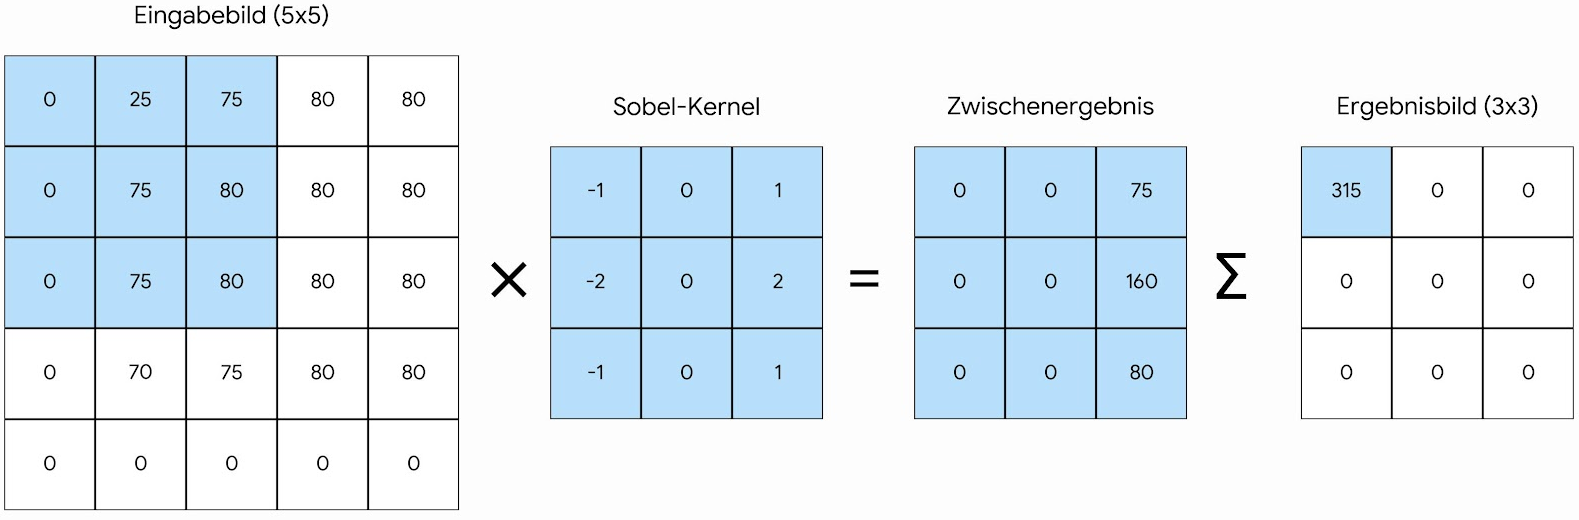

Es ist zunächst der Filterkern mit einem Ausschnitt des Bildes zu multiplizieren und anschließend die Summe des Ergebnisses in das entsprechende Pixel des Ergebnisbildes einzutragen.

1. Erstellen Sie ein leeres 2D-Array (`image_fold = np.zeros(...)`), welches zwei Zeilen und zwei Spalten weniger als das Originalbild aufweist.
2. Erstellen Sie die Filter-Matrix `filter_kernel` als 2D-Array (3x3).
3. Wenden Sie das Filter auf das Bild an:
    - Iterieren Sie mit zwei ineinander geschachtelten for-Schleifen (eine für die x-Richtung, eine für die y-Richtung) über das leere Bild.
    - Indizieren Sie das Originalbild und multiplizieren einen 3x3-Bildausschnitt elementweise mit dem Filter.
    - Weisen Sie die Summe des Ergebnisses der Multiplikation dem indizierten Pixel im Ergebnisbild zu -- Sie können `np.sum` nutzen.
4. Wandeln Sie die Pixelwerte in Absolutwerte um. Nutzen Sie `image_fold = np.abs(...)`.
5. Begrenzen Sie den Wertebereich auf [0,255] mit `image_fold = np.clip(..., 0, 255)`.

**d)** Stellen Sie das Bild dar. 

- Nutzen Sie `.imshow(image_fold, cmap='gray', vmin=0, vmax=255)`.
- Beschriften Sie die x-Achse mit *Pixelindex x*.
- Beschriften Sie die y-Achse mit *Pixelindex y*.

**Anmerkung:**

Die Qualität der Kantenerkennung kann durch eine vorherige Tiefpassfilterung (entfernt das Rauschen) und durch zusätzliche Auswertung der Ableitungen in y-Richtung (das verwendete Sobel-Filter ermittelt die Ableitungen in x-Richtung) erheblich verbessert werden. Durch eine Transponierung der Filter-Matrix können die Ableitungen in y-Richtung ermittelt werden.

## 2. Aufgabe

Erstellen Sie eine 2D-Heatmap und einen Konturplot einer mathematischen Funktion, wobei die Datenpunkte untypischerweise manuell über Schleifen berechnet werden sollen.

1. Stützstellen erzeugen: Erstellen Sie zwei NumPy-Arrays `x` und `y` mit $x\in[-\pi, \pi]$ und $y\in[-2\pi,2\pi]$ mit jeweils 50 Werten. Verwenden Sie `np.linspace`.
2. Gitter erzeugen: Nutzen Sie `np.meshgrid`, um daraus die Koordinaten-Matrizen `X` und `Y` zu erzeugen.
3. Daten berechnen:
    - Legen Sie eine Matrix `Z` der passenden Größe an, die zunächst nur aus Nullen besteht (nutzen Sie `.shape` von `X` oder `Y`).
    - Berechnen Sie die Werte für `Z` mithilfe von zwei ineinander geschachtelten for-Schleifen.
    Die Funktion soll lauten: 
    $$
    f(x,y)=\sin(x)\cdot\cos(y).
    $$
4. Visualisierung: Erstellen Sie eine Abbildung mit zwei nebeneinander angeordneten Subplots.
    - Linker Subplot: 
        - Stellen Sie `Z` als Heatmap unter Verwendung von `.pcolormesh` dar.
        - Beschriften Sie die x-Achse mit *x* und die y-Achse mit *y*.
        - Beschriften Sie die Abbildung mit *Heatmap*.
    - Rechter Subplot: 
        - Stellen Sie `Z` als Konturplot mit `.contour` dar.
        - Beschriften Sie die x-Achse mit *x* und die y-Achse mit *y*.
        - Beschriften Sie die Abbildung mit *Konturplot*. 

**Hinweis:**

- 3.: Sie können Ihre Berechnung mit `Z_ref = np.sin(X)*np.cos(Y)` prüfen.
- 4.: Verwenden Sie `plt.tight_layout()` für einen *schönen* Plot.

## 3. Aufgabe: Näherung der Ableitung der Sigmoidfunktion

In dieser Aufgabe soll die Ableitung der Sigmoidfunktion durch den [Differenzenquotienten](https://de.wikipedia.org/wiki/Differenzenquotient) näherungsweise berechnet werden. 

Der Differenzenquotient approximiert die Ableitung über die Steigung zwischen benachbarten Punkten. Es wird der Vorwärts-Differenzenquotient, welcher über

$$
\frac{\text d\,f(x)}{\text d\,x} \approx \frac{\Delta f}{\Delta x} = \frac{f(x + h) - f(x)}{(x + h) - x},\qquad h>0
$$

gegeben ist, genutzt. Zur Berechnung der Ableitung an einer Stelle $x_1$ wird entsprechend der nächste Punkt an der Stelle $x_2:= x_1 + h$ verwendet.

**a)** Implementieren Sie die Sigmoidfunktion und deren Ableitung

1. Implementieren Sie die Sigmoidfunktion unter dem Funktionsnamen `sigmoid`:
$$
    \sigma(x) = \frac{1}{1 + e^{-x}} 
$$

2. Implementieren Sie die Ableitung der Sigmoidfunktion unter dem Funktionsnamen `dsigmoid_dx`:
$$
    \frac{\text d\,\sigma(x)}{\text d\,x} = \sigma(x)\cdot(1-\sigma(x)).
$$


**b)** Erstellen Sie ein Array `x = np.linspace(-5, 5, 30)`. Berechnen Sie für jede Stützstelle die Sigmoidfunktion und weisen Sie die berechneten Werte einer Variablen `y` zu.

**c)** Berechnen Sie die Ableitung.

1. Berechnen Sie die analytische Ableitung unter Verwendung der Funktion `dsigmoid_dx` und weisen Sie die Ergebnisse einer Variablen `dy_dx` zu.
2. Berechnen Sie die Ableitung unter Verwendung des Differenzenquotienten und weisen Sie die Ergebnisse einer Variablen `dy_dx_approx` zu. Nutzen Sie [`np.diff`](https://numpy.org/doc/stable/reference/generated/numpy.diff.html).
    $$
    \frac{\Delta f}{\Delta x} = \frac{f(x + h) - f(x)}{(x + h) - x},\qquad h>0
    $$

**Hinweis:**

- 2.: Wird `np.diff` auf ein Array angewendet, erzeugt dies ein Array mit den Differenzen der benachbarten Elemente des Ausgangsarrays. Im übertragenen Sinne wird also aus dem Array `x` ($x$) ein neues Array `delta_x` ($\Delta x$) erzeugt.

**d)** Stellen Sie die Sigmoidfunktion sowie die Ableitung (analytisch und numerisch) grafisch dar.

- Die Plots `.plot` haben die Reihenfolge: Sigmoidfunktion, analytische Ableitung, numerische Ableitung. 
- Beschriften Sie die x-Achse mit *x*.
- Fügen Sie eine Legende hinzu. Kopieren Sie die folgenden Labels aus dem Text:
    - Geben Sie der Sigmoidfunktion das Label `r'$\sigma(x)$'`
    - Geben Sie der analytischen Ableitung das Label `r'$\frac{\mathrm{d}\,\sigma(x)}{\mathrm{d}\,x}$'`
    - Geben Sie dem Differenzenquotienten das Label `r'$\frac{\Delta \sigma(x)}{\Delta x}$'`
- Fügen Sie ein Seitengitter hinzu.

**Hinweis:**

- Das Array `dy_dx_approx` hat ein Element weniger als `dy_dx` bzw. `x` (vergleichen Sie mit `len`). Wählen Sie für den Plot von `dy_dx_approx` die korrekten Elemente aus `x` für die x-Achse; indizieren Sie.

## 4. Aufgabe: Summe der Vielfachen von 5 und 7

In dieser Aufgabe soll die Summe aller Vielfachen von 5 und 7 bis zu einer gegebenen natürlichen Zahl berechnet werden. Ist beispielsweise die Zahl 20 gegeben, dann lauten die Vielfachen von 5 und 7: 5, 7, 10, 14, 15, 20. Die Summe dieser Zahlen ist 71.

Implementieren Sie eine Funktion, welche die Summe der Vielfachen bis zu einer gegebenen Zahl berechnet. Der Prototyp sei über
```python
    def calc_multiples_of_5_or_7(number):
```
gegeben.

Wie lautet die Summe aller Vielfachen von 5 und von 7 bis 1000?

**Hinweis:**

- Sie können mehrere Bedingungen mit `or` verknüpfen.
- Nutzen Sie den Modulo-Operator `%`.
- Prüfen Sie zunächst, ob `calc_multiples_of_5_or_7(20)` den Wert `71` berechnet.

**Anmerkung:**

Diese Aufgabe wurde von Aufgabe 1 aus [Project-Euler](https://projecteuler.net/problem=1) abgeleitet.

## 5. Aufgabe: Matrixmultiplikation

Es soll eine Funktion zur Matrix-Multiplikation umgesetzt werden. Die Funktion hat den Prototypen

```python
    def matmul(a, b):
        """Matrix multiplication.

        This function calculates the matrix product of two matrices:
            c = a @ b
        An error is raised when at least one of the matrices is not two
        dimensional. Also an error is raised when their shapes do not match.

        Parameters
        ----------
        a : numpy array
            Left factor of the matrix multiplication.
        b : numpy array
            Right factor of the matrix multiplication.

        Returns
        -------
        numpy array
            Two-dimensional array containing the resulting matrix.
        """
```

Die Funktion berechnet das Matrix-Produkt der Matrizen `a` und `b`. In Form eines NumPy-Arrays zeichnen sich Matrizen dadurch aus, dass sie zweidimensional sind. Gehen Sie bei Ihrer Umsetzung folgendermaßen vor:

1. Prüfen Sie zunächst, ob beide Matrizen zweidimensional sind. Wenn dies nicht der Fall ist, werfen Sie einen Fehler mit `raise ValueError('invalid matrix dimensions')`.
2. Prüfen Sie anschließend anhand der Anzahl der Zeilen und Spalten, ob mit den gegebenen Matrizen eine Matrix-Multiplikation durchführbar ist. Geben Sie einen Fehler aus, wenn die Dimensionen nicht zueinander passen; `raise ValueError('shapes do not match')`.
3. Berechnen Sie das Matrix-Produkt unter Verwendung von Schleifen. Legen Sie zunächst eine Ergebnismatrix passender Dimension an mit `c = np.zeros(...)`. Die Nutzung von `.dot`, `np.dot`, `np.matmul`, `@` oder ähnlicher verfügbarer Funktionen ist hier nicht gestattet.

Testen Sie Ihre Funktion mit

1. $a = \begin{bmatrix}1 & 2 & 3\end{bmatrix}$, $b = \begin{bmatrix}4 \\ 5 \\ 6\end{bmatrix}$
2. $a = \begin{bmatrix}1 & 2 & 3 \\ 4 & 5 & 6\end{bmatrix}$, $b = a^\mathrm T$

## 6. Aufgabe: Sekantenverfahren

Es soll das [Sekantenverfahren](https://de.wikipedia.org/wiki/Sekantenverfahren) umgesetzt werden. Mit dem Sekantenverfahren kann die Nullstelle einer Funktion mit einer unabhängigen Variablen ermittelt werden.

Die Iterationsvorschrift lautet:
$$
    x_{i+1} = x_i - \frac{x_i - x_{i-1}}{f(x_i) - f(x_{i-1})}f(x_i). 
$$

Es wird mit zwei Näherungswerten $x_0$ und $x_1$ begonnen. Mit jeder Iteration nähert sich $x$ der tatsächlichen Lösung an.

In dieser Aufgabe soll die Nullstelle der Funktion 

$$
    f(x) = 4(x-2)^3 + x
$$

ermittelt werden. 



**a)** Stellen Sie die Funktion $f(x)$ für $x\in[-2,5]$ grafisch dar.

1. Implementieren Sie $f(x)$ unter dem Prototypen 
```python
    def f(x):
```
2. Definieren Sie die Stützstellen mit `x = np.linspace(-2, 5, 100)`.
3. Erstellen Sie eine Abbildung mit folgenden Eigenschaften:
    - Darstellung von f(x) mit `.plot`
    - x-Achsen-Beschriftung: `x`
    - y-Achsen-Beschriftung: `f(x)`
    - Seitengitter

**b)** Implementieren Sie das Sekantenverfahren. Als Startwerte für die Iterationsvorschrift werden $x_0 := -2$ und $x_1 := 5$ gewählt. Brechen Sie die Berechnung ab, sobald $|x_{i} - x_{i-1}| < 1E-6$ gilt. 

Weisen Sie nach der Berechnung den folgenden Variablen die genannten Inhalte zu: 

- `root`: Nullstelle der Funktion
- `value`: Funktionswert an der Nullstelle
- `nof_iterations`: Anzahl der durchgeführten Iterationen 